# AgroPest-12 Part B: DINOv3-Guided YOLOv12m Pretraining

**Student:** randomly initialized `yolo12m.yaml` backbone  \n
**Teacher:** frozen released DINOv3 ViT-B/16  \n
**Data:** `ssl_pool/images` only, 9,180 images  \n
**Runtime:** Kaggle T4 x2 with DistributedDataParallel

This is traditional standalone PyTorch DINOv3-guided distillation. It does not use Lightly, PyTorch Lightning, `ssl-detection-lab`, or `ssldet`. Labels, fine-tuning images, validation images, and test images are never read.

## Method And Protocol

The frozen external-pretrained DINOv3 ViT-B/16 teacher provides 768-dimensional global class-token and 14x14 dense patch-token targets for the same augmented image processed by the randomly initialized YOLOv12m student. The student minimizes equal-weight global and dense cosine-regression losses. Only the student backbone transfers downstream; the teacher, projectors, optimizer, scheduler, detector neck, and detector head never transfer.

This is DINOv3-guided feature distillation, not a reproduction of Meta's full DINOv3 recipe. It must be reported as using an externally pretrained teacher.

In [1]:
# Keep Kaggle's CUDA-matched PyTorch. Internet must be enabled for torch.hub to obtain DINOv3 source code.
import subprocess, sys
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '--upgrade',
    'ultralytics>=8.4.96', 'scikit-learn', 'seaborn', 'torchmetrics', 'kagglehub',
])

import torch, ultralytics
assert torch.cuda.is_available(), 'Enable two T4 GPUs before running this notebook.'
assert torch.cuda.device_count() == 2, f'Require exactly two visible T4 GPUs, found {torch.cuda.device_count()}.'
print('PyTorch:', torch.__version__)
print('Ultralytics:', ultralytics.__version__)
print('GPUs:', [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
torch.set_float32_matmul_precision('high')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 110.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 17.3 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.10.0+cu128
Ultralytics: 8.4.117
GPUs: ['Tesla T4', 'Tesla T4']


In [2]:
# ============================================================
# CONFIG: every value is fixed and viva-explainable
# ============================================================
from dataclasses import asdict, dataclass
from pathlib import Path

@dataclass
class CFG:
    # Only this image directory is used during pretraining.
    ssl_pool: str = '/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe/ssl_pool/images'
    output_dir: str = '/kaggle/working/partB_04a_dinov3_yolo12m'
    # Downloaded automatically from the public Kaggle teacher-weights dataset.
    teacher_dataset: str = 'mrifatrashid/dinov3-weigths'
    teacher_filename: str = 'dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth'
    teacher_ckpt: str = ''

    seed: int = 445
    model_yaml: str = 'yolo12m.yaml'  # Random student, never yolo12m.pt.
    image_size: int = 224             # ViT-B/16 gives a 14x14 teacher patch grid.
    teacher_embed_dim: int = 768
    teacher_patch_size: int = 16

    epochs: int = 30
    per_gpu_batch: int = 4            # Per GPU; fits frozen ViT-B/16 plus YOLOv12m on a T4.
    grad_accum: int = 4               # Effective global optimization batch: 4 x 2 x 4 = 32.
    workers: int = 2
    amp: bool = True
    resume: bool = False              # Set True only after an interrupted run with last_ssl.pt present.

    learning_rate: float = 3e-4
    min_learning_rate: float = 3e-6
    warmup_epochs: int = 1
    weight_decay: float = 1e-4
    gradient_clip_norm: float = 5.0
    global_loss_weight: float = 1.0
    dense_loss_weight: float = 1.0
    diagnostic_images: int = 240
    retrieval_queries: int = 4
    retrieval_neighbors: int = 5

cfg = CFG()
SSL_IMAGES = Path(cfg.ssl_pool)
OUTPUT_DIR = Path(cfg.output_dir)
assert SSL_IMAGES.is_dir(), f'Attach AgroPest-12-PartB-Safe. Missing: {SSL_IMAGES}'
# Kaggle Internet must be enabled. This obtains only the public teacher dataset; no manual input is required.
import kagglehub
teacher_root = Path(kagglehub.dataset_download(cfg.teacher_dataset))
teacher_matches = sorted(teacher_root.rglob(cfg.teacher_filename))
assert teacher_matches, f'Could not find {cfg.teacher_filename} after downloading {cfg.teacher_dataset}'
cfg.teacher_ckpt = str(teacher_matches[0])
TEACHER_CKPT = Path(cfg.teacher_ckpt)
assert TEACHER_CKPT.is_file()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(asdict(cfg))
print('Automatically downloaded DINOv3 teacher:', TEACHER_CKPT, f'({TEACHER_CKPT.stat().st_size / 1e6:.1f} MB)')

{'ssl_pool': '/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe/ssl_pool/images', 'output_dir': '/kaggle/working/partB_04a_dinov3_yolo12m', 'teacher_dataset': 'mrifatrashid/dinov3-weigths', 'teacher_filename': 'dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth', 'teacher_ckpt': '/kaggle/input/datasets/mrifatrashid/dinov3-weigths/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth', 'seed': 445, 'model_yaml': 'yolo12m.yaml', 'image_size': 224, 'teacher_embed_dim': 768, 'teacher_patch_size': 16, 'epochs': 30, 'per_gpu_batch': 4, 'grad_accum': 4, 'workers': 2, 'amp': True, 'resume': False, 'learning_rate': 0.0003, 'min_learning_rate': 3e-06, 'warmup_epochs': 1, 'weight_decay': 0.0001, 'gradient_clip_norm': 5.0, 'global_loss_weight': 1.0, 'dense_loss_weight': 1.0, 'diagnostic_images': 240, 'retrieval_queries': 4, 'retrieval_neighbors': 5}
Automatically downloaded DINOv3 teacher: /kaggle/input/datasets/mrifatrashid/dinov3-weigths/dinov3_vitb16_pretrain_lvd1689m-73cec8be

## Configuration Notes

Each DDP process uses four images, so four gradient-accumulation steps produce an effective global optimization batch of 32. This non-contrastive objective has no in-batch negatives, so accumulation smooths optimizer updates without changing the teacher targets. The teacher is frozen, AMP reduces T4 memory use, and the one-epoch Colab validation completed the full SSL pool in 392.6 seconds at batch size eight on one T4.

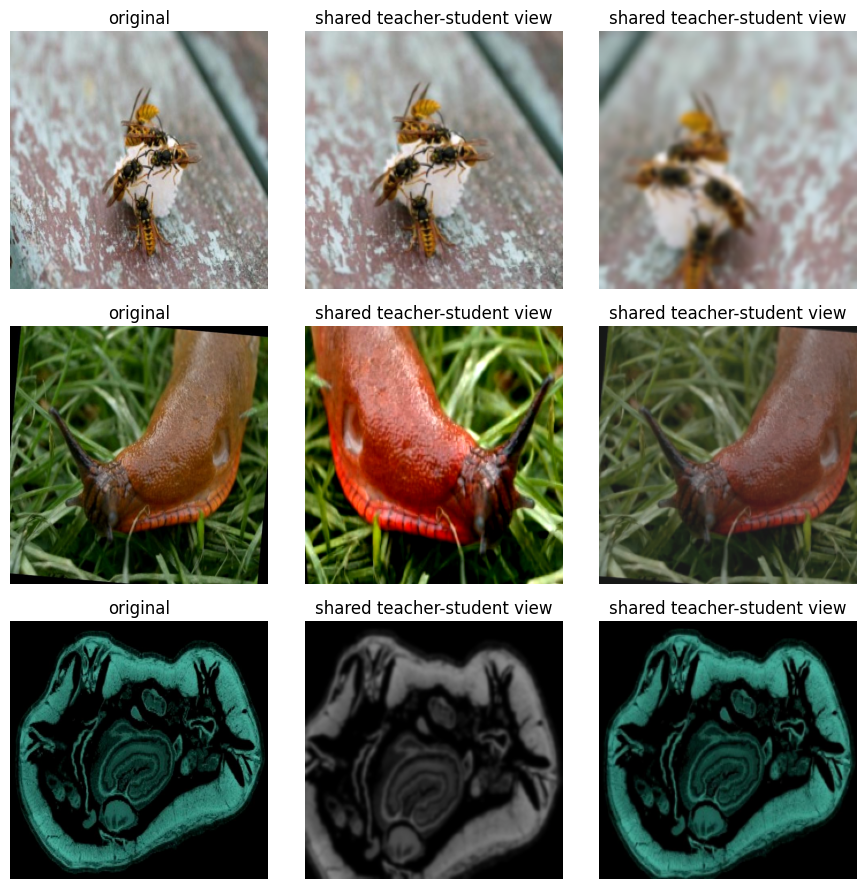

Validated 9,180 image-only SSL-pool files.


In [3]:
# Strict image-only input audit and shared-view augmentation preview.
import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision import transforms

IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
ssl_paths = sorted(path for path in SSL_IMAGES.iterdir() if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES)
assert len(ssl_paths) == 9180, f'Expected 9,180 SSL-pool images, found {len(ssl_paths)}'
assert not any(SSL_IMAGES.rglob('*.txt')), 'SSL pool must not contain labels.'

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(cfg.image_size, scale=(0.5, 1.0), ratio=(0.75, 4 / 3)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.20, 0.06)], p=0.8),
    transforms.RandomGrayscale(p=0.1),
    transforms.RandomApply([transforms.GaussianBlur(23, sigma=(0.1, 2.0))], p=0.5),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

mean = np.asarray(IMAGENET_MEAN).reshape(3, 1, 1); std = np.asarray(IMAGENET_STD).reshape(3, 1, 1)
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, path in enumerate(random.Random(cfg.seed).sample(ssl_paths, 3)):
    with Image.open(path) as image:
        original = image.convert('RGB')
        axes[row, 0].imshow(original)
    axes[row, 0].set_title('original')
    for column in (1, 2):
        view = train_transform(original).numpy()
        axes[row, column].imshow(np.transpose(np.clip(view * std + mean, 0, 1), (1, 2, 0)))
        axes[row, column].set_title('shared teacher-student view')
    for axis in axes[row]: axis.axis('off')
plt.tight_layout(); plt.show()
print(f'Validated {len(ssl_paths):,} image-only SSL-pool files.')

## DDP Training

The script below uses NCCL, `DistributedSampler`, `DistributedDataParallel`, AMP, finite-loss checks, gradient clipping, and rank-zero-only writes. It executes the original Ultralytics YAML backbone graph through each layer's `f`, `i`, and `save` metadata rather than treating the backbone as a sequential slice.

In [4]:
# Write the standalone DDP implementation to /kaggle/working/.
# It is self-contained so the published output records the exact training mechanism.
import json
SCRIPT_PATH = OUTPUT_DIR / 'pretrain_dinov3_yolo12m.py'
SCRIPT_PATH.write_text(r'''
import argparse, csv, json, math, os, random, time
from copy import deepcopy
from pathlib import Path
import numpy as np
import torch
import torch.distributed as dist
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, Dataset
from torch.utils.data.distributed import DistributedSampler
from torchvision import transforms
from ultralytics import YOLO

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

class ImageDataset(Dataset):
    def __init__(self, paths, transform): self.paths, self.transform = list(paths), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image: return self.transform(image.convert('RGB'))

def train_transform(size):
    return transforms.Compose([
        transforms.RandomResizedCrop(size, scale=(0.5, 1.0), ratio=(0.75, 4 / 3)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.20, 0.06)], p=0.8),
        transforms.RandomGrayscale(p=0.1),
        transforms.RandomApply([transforms.GaussianBlur(23, sigma=(0.1, 2.0))], p=0.5),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])

class YOLOGraphBackbone(nn.Module):
    def __init__(self, detector):
        super().__init__(); self.backbone_end = len(detector.yaml['backbone']); self.save = set(detector.save)
        self.layers = nn.ModuleDict({str(module.i): module for module in detector.model if module.i < self.backbone_end})
    def forward_feature_map(self, x):
        saved = []
        for module in self.layers.values():
            if module.f != -1:
                x = saved[module.f] if isinstance(module.f, int) else [x if j == -1 else saved[j] for j in module.f]
            x = module(x); saved.append(x if module.i in self.save else None)
        if not isinstance(x, torch.Tensor): raise TypeError('YOLO backbone did not end in a tensor')
        return x
    def forward(self, x): return F.adaptive_avg_pool2d(self.forward_feature_map(x), 1).flatten(1)
    def backbone_state_dict(self):
        state = self.layers.state_dict(); result = {}
        for index in range(self.backbone_end):
            prefix = f'{index}.'
            result.update({f'model.{index}.{key[len(prefix):]}': value.detach().cpu() for key, value in state.items() if key.startswith(prefix)})
        return result

class FrozenTeacher(nn.Module):
    def __init__(self, model, dim, grid):
        super().__init__(); self.model = model.eval(); self.dim, self.grid = dim, grid
        for parameter in self.model.parameters(): parameter.requires_grad_(False)
    @torch.no_grad()
    def forward(self, images):
        output = self.model.forward_features(images)
        patches = output['x_norm_patchtokens'].transpose(1, 2).reshape(images.shape[0], self.dim, self.grid, self.grid)
        return output['x_norm_clstoken'], patches

class Student(nn.Module):
    def __init__(self, encoder, dim, teacher_dim, global_weight, dense_weight):
        super().__init__(); self.encoder = encoder; self.global_weight, self.dense_weight = global_weight, dense_weight
        self.global_head = nn.Sequential(nn.Linear(dim, dim, bias=False), nn.BatchNorm1d(dim), nn.GELU(), nn.Linear(dim, teacher_dim))
        self.dense_head = nn.Conv2d(dim, teacher_dim, 1)
    def forward(self, images, target_global, target_dense):
        features = self.encoder.forward_feature_map(images)
        global_prediction = self.global_head(F.adaptive_avg_pool2d(features, 1).flatten(1))
        dense_prediction = F.interpolate(self.dense_head(features), size=target_dense.shape[-2:], mode='bilinear', align_corners=False)
        global_loss = (1 - F.cosine_similarity(F.normalize(global_prediction, dim=1), F.normalize(target_global, dim=1), dim=1)).mean()
        dense_loss = (1 - F.cosine_similarity(F.normalize(dense_prediction, dim=1), F.normalize(target_dense, dim=1), dim=1)).mean()
        return self.global_weight * global_loss + self.dense_weight * dense_loss, global_loss.detach(), dense_loss.detach()

def build_teacher(cfg, device):
    raw = torch.hub.load('facebookresearch/dinov3', 'dinov3_vitb16', pretrained=False)
    state = torch.load(cfg['teacher_ckpt'], map_location='cpu', weights_only=False)
    raw.load_state_dict(state.get('state_dict', state), strict=True)
    return FrozenTeacher(raw, cfg['teacher_embed_dim'], cfg['image_size'] // cfg['teacher_patch_size']).to(device)

def build_student(cfg, device):
    encoder = YOLOGraphBackbone(YOLO(cfg['model_yaml']).model).to(device)
    with torch.no_grad(): dim = int(encoder(torch.zeros(2, 3, cfg['image_size'], cfg['image_size'], device=device)).shape[1])
    return encoder, dim

def set_lr(optimizer, cfg, update, total, warmup):
    if update < warmup: lr = cfg['learning_rate'] * (0.1 + 0.9 * (update + 1) / max(1, warmup))
    else:
        progress = (update - warmup) / max(1, total - warmup - 1)
        lr = cfg['min_learning_rate'] + (cfg['learning_rate'] - cfg['min_learning_rate']) * 0.5 * (1 + math.cos(math.pi * min(progress, 1)))
    for group in optimizer.param_groups: group['lr'] = lr
    return lr

def export(cfg, model, dim):
    output = Path(cfg['output_dir']); backbone = model.encoder.backbone_state_dict()
    torch.save({'format': 'yolo_backbone_only_v1', 'model_yaml': cfg['model_yaml'], 'backbone_state_dict': backbone, 'feature_dim': dim, 'config': cfg}, output / 'backbone_only.pt')
    detector = YOLO(cfg['model_yaml']).model; detector_state = detector.state_dict()
    expected = {key: value for key, value in detector_state.items() if int(key.split('.')[1]) < model.encoder.backbone_end}
    missing = sorted(set(expected) - set(backbone)); bad_shapes = sorted(key for key in expected if key in backbone and expected[key].shape != backbone[key].shape); extra = sorted(set(backbone) - set(expected))
    assert not missing and not bad_shapes and not extra, {'missing': missing[:5], 'bad_shapes': bad_shapes[:5], 'extra': extra[:5]}
    detector.load_state_dict(backbone, strict=False); detector.args = {'model': cfg['model_yaml'], 'task': 'detect'}
    compatible = output / 'yolo12m_dinov3_backbone.pt'
    torch.save({'model': deepcopy(detector).half().cpu(), 'ema': None, 'updates': 0, 'optimizer': None, 'train_args': detector.args, 'date': time.strftime('%Y-%m-%dT%H:%M:%S')}, compatible)
    report = {'source': 'random yolo12m.yaml distilled with frozen DINOv3 ViT-B/16', 'transferred_component': 'YOLOv12m backbone only', 'excluded_components': ['teacher', 'global_head', 'dense_head', 'optimizer', 'scheduler', 'detector_neck', 'detector_head'], 'backbone_tensor_coverage': {'matched': len(expected), 'expected': len(expected), 'percent': 100.0}, 'artifacts': {'backbone_only': 'backbone_only.pt', 'detector_compatible': compatible.name}}
    (output / 'transfer_report.json').write_text(json.dumps(report, indent=2)); return report

def sanity(cfg):
    device = torch.device('cuda:0'); paths = sorted(path for path in Path(cfg['ssl_pool']).iterdir() if path.suffix.lower() in SUFFIXES)[:2]
    teacher = build_teacher(cfg, device); encoder, dim = build_student(cfg, device); model = Student(encoder, dim, cfg['teacher_embed_dim'], cfg['global_loss_weight'], cfg['dense_loss_weight']).to(device).train()
    images = torch.stack([ImageDataset(paths, train_transform(cfg['image_size']))[index] for index in range(2)]).to(device)
    with torch.no_grad(): target_global, target_dense = teacher(images.float())
    with torch.amp.autocast('cuda', enabled=cfg['amp']): loss, _, _ = model(images, target_global, target_dense)
    assert torch.isfinite(loss); loss.backward(); grad = sum(parameter.grad.detach().norm().item() for parameter in model.encoder.parameters() if parameter.grad is not None)
    assert grad > 0 and all(parameter.grad is None for parameter in teacher.parameters())
    print(json.dumps({'finite_loss': float(loss.detach()), 'student_gradient_norm': grad, 'teacher_gradient_tensors': 0, 'feature_dim': dim}, indent=2))

def train(cfg):
    dist.init_process_group('nccl'); rank, world = dist.get_rank(), dist.get_world_size(); local_rank = int(os.environ['LOCAL_RANK']); torch.cuda.set_device(local_rank); device = torch.device(f'cuda:{local_rank}')
    seed_everything(cfg['seed'] + rank); output = Path(cfg['output_dir']); paths = sorted(path for path in Path(cfg['ssl_pool']).iterdir() if path.suffix.lower() in SUFFIXES)
    assert len(paths) == 9180; sampler = DistributedSampler(paths, num_replicas=world, rank=rank, shuffle=True, seed=cfg['seed'])
    loader = DataLoader(ImageDataset(paths, train_transform(cfg['image_size'])), batch_size=cfg['per_gpu_batch'], sampler=sampler, num_workers=cfg['workers'], pin_memory=True, persistent_workers=cfg['workers'] > 0, drop_last=True)
    teacher = build_teacher(cfg, device); encoder, dim = build_student(cfg, device); model = Student(encoder, dim, cfg['teacher_embed_dim'], cfg['global_loss_weight'], cfg['dense_loss_weight']).to(device); model = DDP(model, device_ids=[local_rank])
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['learning_rate'], weight_decay=cfg['weight_decay']); scaler = torch.amp.GradScaler('cuda', enabled=cfg['amp'])
    updates_per_epoch = math.ceil(len(loader) / cfg['grad_accum']); total_updates = cfg['epochs'] * updates_per_epoch; warmup_updates = cfg['warmup_epochs'] * updates_per_epoch; start_epoch = global_update = 0; best_loss = float('inf'); history = []
    resume_path = output / 'last_ssl.pt'
    if rank == 0 and cfg['resume'] and (output / 'history.csv').is_file():
        with open(output / 'history.csv', newline='') as file: history = list(csv.DictReader(file))
    if cfg['resume'] and resume_path.is_file():
        state = torch.load(resume_path, map_location=device, weights_only=False); model.module.encoder.load_state_dict(state['encoder_state_dict']); model.module.global_head.load_state_dict(state['global_head_state_dict']); model.module.dense_head.load_state_dict(state['dense_head_state_dict']); optimizer.load_state_dict(state['optimizer_state_dict']); scaler.load_state_dict(state['scaler_state_dict']); start_epoch, global_update, best_loss = state['epoch'], state['global_update'], state['best_loss']
    for epoch in range(start_epoch, cfg['epochs']):
        sampler.set_epoch(epoch); model.train(); totals = torch.zeros(3, device=device); started = time.time(); optimizer.zero_grad(set_to_none=True)
        for step, images in enumerate(loader):
            images = images.to(device, non_blocking=True)
            with torch.no_grad(): target_global, target_dense = teacher(images.float())
            with torch.amp.autocast('cuda', enabled=cfg['amp']): loss, global_loss, dense_loss = model(images, target_global, target_dense); scaled = loss / cfg['grad_accum']
            assert torch.isfinite(scaled), f'Non-finite loss at epoch {epoch + 1}, step {step}'
            scaler.scale(scaled).backward(); totals += torch.stack((loss.detach(), global_loss, dense_loss))
            if (step + 1) % cfg['grad_accum'] == 0 or (step + 1) == len(loader):
                lr = set_lr(optimizer, cfg, global_update, total_updates, warmup_updates); scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['gradient_clip_norm']); scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); global_update += 1
        dist.all_reduce(totals, op=dist.ReduceOp.SUM); averages = (totals / (len(loader) * world)).tolist()
        if rank == 0:
            record = {'epoch': epoch + 1, 'images': len(paths), 'steps_per_rank': len(loader), 'loss': averages[0], 'global_loss': averages[1], 'dense_loss': averages[2], 'learning_rate': lr, 'seconds': round(time.time() - started, 1)}; history.append(record); best_loss = min(best_loss, record['loss'])
            state = {'epoch': epoch + 1, 'global_update': global_update, 'best_loss': best_loss, 'feature_dim': dim, 'encoder_state_dict': {key: value.cpu() for key, value in model.module.encoder.state_dict().items()}, 'global_head_state_dict': {key: value.cpu() for key, value in model.module.global_head.state_dict().items()}, 'dense_head_state_dict': {key: value.cpu() for key, value in model.module.dense_head.state_dict().items()}, 'optimizer_state_dict': optimizer.state_dict(), 'scaler_state_dict': scaler.state_dict(), 'config': cfg}
            torch.save(state, resume_path);
            if record['loss'] <= best_loss: torch.save(state, output / 'best_ssl.pt')
            with open(output / 'history.csv', 'w', newline='') as file: writer = csv.DictWriter(file, fieldnames=history[0].keys()); writer.writeheader(); writer.writerows(history)
            print(f"Epoch {epoch + 1}/{cfg['epochs']} | loss {record['loss']:.4f} | global {record['global_loss']:.4f} | dense {record['dense_loss']:.4f} | {record['seconds']:.0f}s", flush=True)
        dist.barrier()
    if rank == 0:
        report = export(cfg, model.module, dim); manifest = {'config': cfg, 'world_size': world, 'ssl_images': len(paths), 'teacher_frozen': all(not parameter.requires_grad for parameter in teacher.parameters()), 'history': history, 'transfer_report': report}; (output / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
    dist.barrier(); dist.destroy_process_group()

if __name__ == '__main__':
    parser = argparse.ArgumentParser(); parser.add_argument('--config', required=True); parser.add_argument('--sanity', action='store_true'); args = parser.parse_args(); cfg = json.loads(Path(args.config).read_text())
    sanity(cfg) if args.sanity else train(cfg)
''')
CONFIG_PATH = OUTPUT_DIR / 'config.json'
CONFIG_PATH.write_text(json.dumps(asdict(cfg), indent=2))
print('Wrote:', SCRIPT_PATH, CONFIG_PATH)

Wrote: /kaggle/working/partB_04a_dinov3_yolo12m/pretrain_dinov3_yolo12m.py /kaggle/working/partB_04a_dinov3_yolo12m/config.json


In [5]:
# Finite-loss and gradient sanity check on one GPU before DDP.
subprocess.check_call([sys.executable, str(SCRIPT_PATH), '--config', str(CONFIG_PATH), '--sanity'])

Downloading: "https://github.com/facebookresearch/dinov3/zipball/main" to /root/.cache/torch/hub/main.zip
{
  "finite_loss": 2.0245797634124756,
  "student_gradient_norm": 326.87274246277525,
  "teacher_gradient_tensors": 0,
  "feature_dim": 512
}


0

In [6]:
# Launch exactly one NCCL process per T4 GPU. This is the 30-epoch pretraining run.
subprocess.check_call([
    sys.executable, '-m', 'torch.distributed.run', '--standalone', '--nproc_per_node=2',
    str(SCRIPT_PATH), '--config', str(CONFIG_PATH),
])

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov3_main
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov3_main


Epoch 1/30 | loss 1.2311 | global 0.7171 | dense 0.5140 | 228s


/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Epoch 2/30 | loss 1.0511 | global 0.6610 | dense 0.3901 | 215s
Epoch 3/30 | loss 1.0308 | global 0.6502 | dense 0.3806 | 218s
Epoch 4/30 | loss 1.0108 | global 0.6385 | dense 0.3723 | 217s
Epoch 5/30 | loss 0.9947 | global 0.6277 | dense 0.3670 | 218s
Epoch 6/30 | loss 0.9762 | global 0.6162 | dense 0.3600 | 217s
Epoch 7/30 | loss 0.9658 | global 0.6079 | dense 0.3579 | 227s
Epoch 8/30 | loss 0.9498 | global 0.5966 | dense 0.3533 | 218s
Epoch 9/30 | loss 0.9395 | global 0.5889 | dense 0.3505 | 214s
Epoch 10/30 | loss 0.9265 | global 0.5794 | dense 0.3471 | 214s
Epoch 11/30 | loss 0.9086 | global 0.5673 | dense 0.3414 | 213s
Epoch 12/30 | loss 0.8975 | global 0.5598 | dense 0.3377 | 221s
Epoch 13/30 | loss 0.8853 | global 0.5511 | dense 0.3343 | 216s
Epoch 14/30 | loss 0.8733 | global 0.5427 | dense 0.3305 | 217s
Epoch 15/30 | loss 0.8655 | global 0.5374 | dense 0.3281 | 214s
Epoch 16/30 | loss 0.8522 | global 0.5283 | dense 0.3238 | 218s
Epoch 17/30 | loss 0.8425 | global 0.5212 | dens

0

## Representation Diagnostics And Handoff

After training, the notebook plots the loss curve and produces t-SNE plus query/top-five cosine-nearest-neighbour panels from a fixed SSL-pool sample. These are image-only diagnostics and make no label-based claims. The export enforces 100% key-and-shape coverage for the YOLOv12m backbone before writing a detector-compatible checkpoint.

    epoch  images  steps_per_rank      loss  global_loss  dense_loss  \
25     26    9180            1147  0.784118     0.481147    0.302971   
26     27    9180            1147  0.779814     0.478196    0.301619   
27     28    9180            1147  0.777681     0.477007    0.300674   
28     29    9180            1147  0.775616     0.475404    0.300212   
29     30    9180            1147  0.777086     0.476233    0.300853   

    learning_rate  seconds  
25       0.000017    215.8  
26       0.000011    215.5  
27       0.000006    212.9  
28       0.000004    214.1  
29       0.000003    220.8  
Detector-compatible checkpoint: /kaggle/working/partB_04a_dinov3_yolo12m/yolo12m_dinov3_backbone.pt
Transfer report: {'matched': 402, 'expected': 402, 'percent': 100.0}


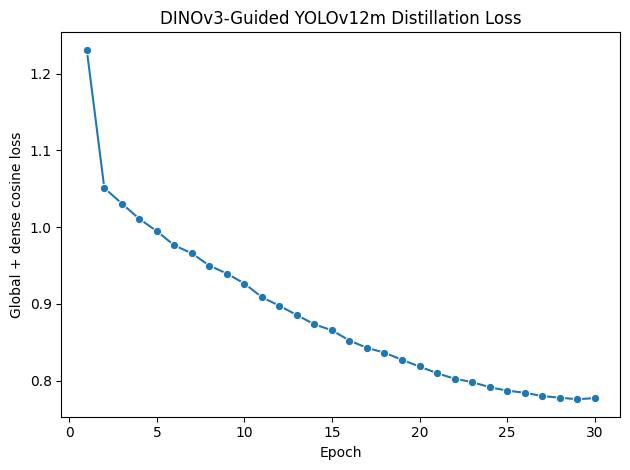

In [7]:
import json
import pandas as pd
import seaborn as sns
from ultralytics import YOLO

history = pd.read_csv(OUTPUT_DIR / 'history.csv')
report = json.loads((OUTPUT_DIR / 'transfer_report.json').read_text())
required = {'best_ssl.pt', 'last_ssl.pt', 'history.csv', 'run_manifest.json', 'backbone_only.pt', 'yolo12m_dinov3_backbone.pt', 'transfer_report.json'}
produced = {path.name for path in OUTPUT_DIR.iterdir()}
assert required <= produced, f'Missing artifacts: {sorted(required - produced)}'
assert report['backbone_tensor_coverage']['percent'] == 100.0
reloaded = YOLO(str(OUTPUT_DIR / 'yolo12m_dinov3_backbone.pt'))
assert reloaded.task == 'detect'

axis = sns.lineplot(data=history, x='epoch', y='loss', marker='o')
axis.set(title='DINOv3-Guided YOLOv12m Distillation Loss', xlabel='Epoch', ylabel='Global + dense cosine loss')
axis.figure.tight_layout(); axis.figure.savefig(OUTPUT_DIR / 'dinov3_distillation_loss.png', dpi=160)
print(history.tail())
print('Detector-compatible checkpoint:', OUTPUT_DIR / 'yolo12m_dinov3_backbone.pt')
print('Transfer report:', report['backbone_tensor_coverage'])

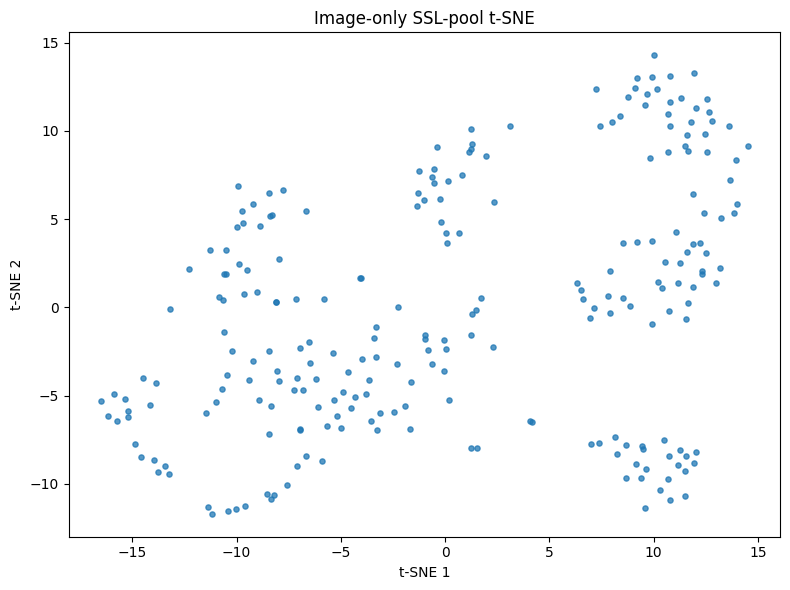

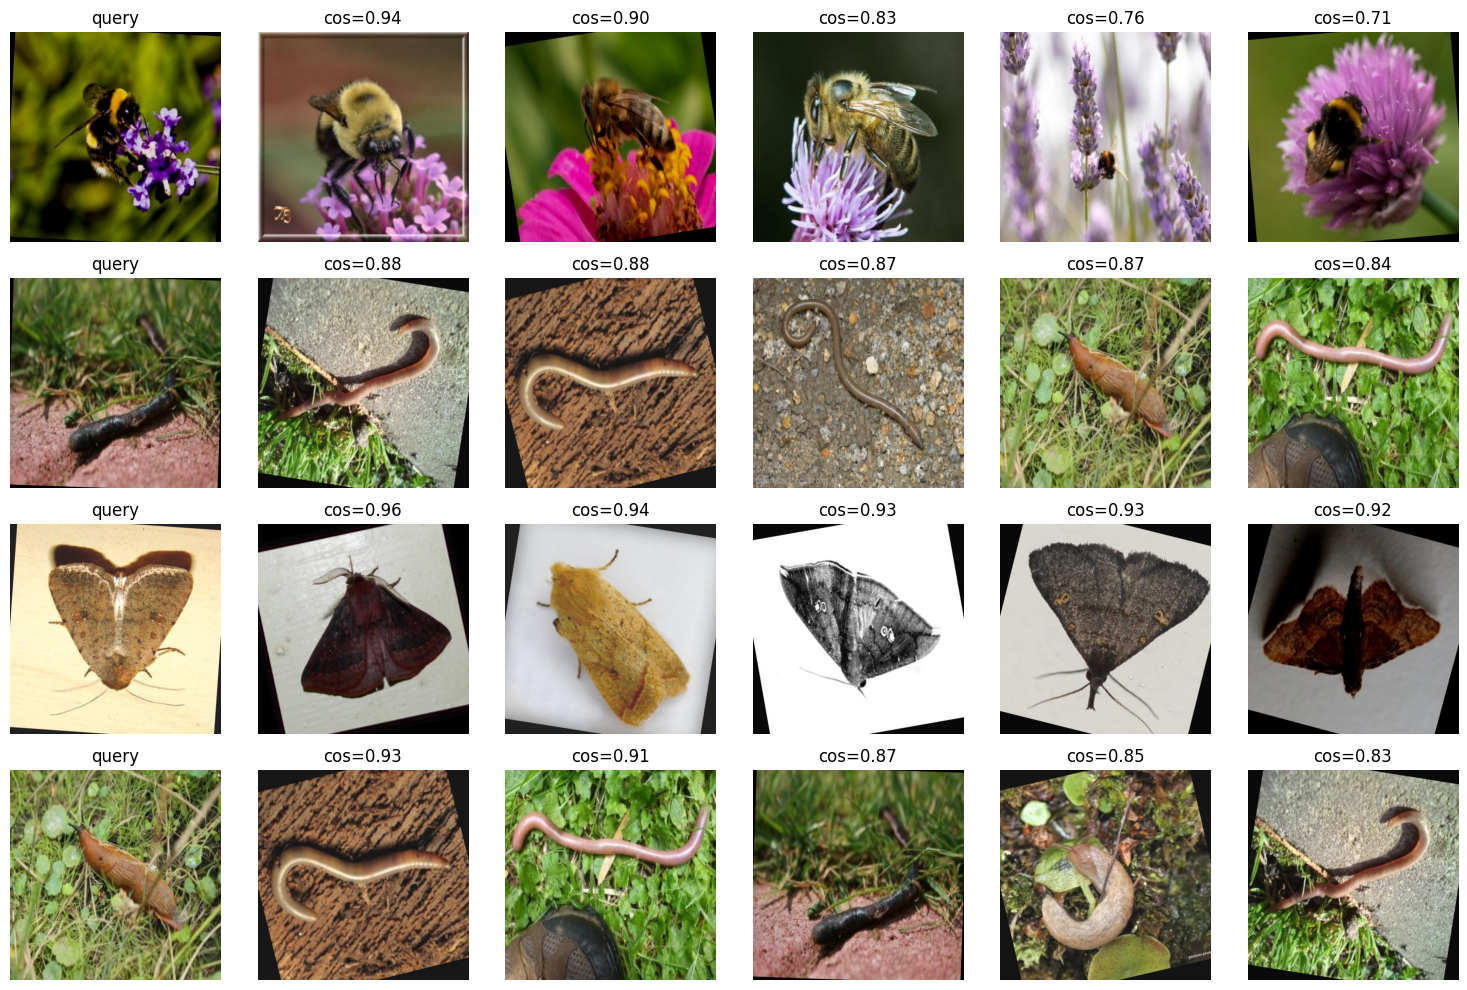

In [8]:
# Image-only t-SNE and cosine retrieval diagnostics.
from sklearn.manifold import TSNE
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

class DiagnosticEncoder(nn.Module):
    def __init__(self, detector):
        super().__init__(); self.model = detector; self.backbone_end = len(detector.yaml['backbone']); self.save = set(detector.save)
    def forward(self, x):
        saved = []
        for module in self.model.model:
            if module.i >= self.backbone_end: break
            if module.f != -1: x = saved[module.f] if isinstance(module.f, int) else [x if j == -1 else saved[j] for j in module.f]
            x = module(x); saved.append(x if module.i in self.save else None)
        return F.adaptive_avg_pool2d(x, 1).flatten(1)

eval_transform = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(cfg.image_size), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
class DiagnosticDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image: return eval_transform(image.convert('RGB'))

diagnostic_paths = random.Random(cfg.seed).sample(ssl_paths, cfg.diagnostic_images)
device = torch.device('cuda:0')
encoder = DiagnosticEncoder(YOLO(str(OUTPUT_DIR / 'yolo12m_dinov3_backbone.pt')).model).to(device).eval()
vectors = []
with torch.inference_mode():
    for images in DataLoader(DiagnosticDataset(diagnostic_paths), batch_size=32, num_workers=2, pin_memory=True):
        vectors.append(F.normalize(encoder(images.to(device, non_blocking=True)), dim=1).cpu())
embeddings = torch.cat(vectors).numpy()
coordinates = TSNE(n_components=2, perplexity=min(30, len(embeddings) // 4), init='pca', learning_rate='auto', random_state=cfg.seed).fit_transform(embeddings)
fig, axis = plt.subplots(figsize=(8, 6)); axis.scatter(coordinates[:, 0], coordinates[:, 1], s=14, alpha=0.75); axis.set(title='Image-only SSL-pool t-SNE', xlabel='t-SNE 1', ylabel='t-SNE 2'); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'dinov3_tsne_ssl_pool.png', dpi=160); plt.show()

similarities = embeddings @ embeddings.T; np.fill_diagonal(similarities, -np.inf)
query_indices = random.Random(cfg.seed).sample(range(len(diagnostic_paths)), cfg.retrieval_queries)
fig, axes = plt.subplots(cfg.retrieval_queries, cfg.retrieval_neighbors + 1, figsize=(15, 10))
for row, query in enumerate(query_indices):
    indexes = [query, *np.argsort(-similarities[query])[:cfg.retrieval_neighbors]]
    for column, index in enumerate(indexes):
        with Image.open(diagnostic_paths[index]) as image: axes[row, column].imshow(image.convert('RGB'))
        axes[row, column].set_title('query' if column == 0 else f'cos={similarities[query, index]:.2f}'); axes[row, column].axis('off')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'dinov3_nearest_neighbors.png', dpi=160); plt.show()

## Publication And Viva Notes

Publish the full `/kaggle/working/partB_04a_dinov3_yolo12m/` directory as a Kaggle dataset. Notebook `04b` attaches that exact output and uses `yolo12m_dinov3_backbone.pt` with `transfer_report.json`. The notebook automatically downloads the public DINOv3 teacher dataset through `kagglehub`; Kaggle Internet must remain enabled. Explain that this method uses a frozen external DINOv3 teacher, while only the trained random-initialized YOLOv12m student backbone is transferred.